# Experiment 5: drop one phone (ablation)

Same question as `experiment_zones.ipynb` (which 50 cm zone is the speaker in?), same data, windows, split, zones and 8-band features. **What is swapped: the set of phones.** The model is trained and tested with all three phones, and with each phone left out in turn (A+B, A+C, B+C), to see how much each phone contributes and whether two phones are enough.

## What is the same, what differs from the zone notebooks
* **Same:** the synced recordings (`audio_abc.wav`), 1 s windows every 0.5 s, 16 kHz, 300–4000 Hz band-pass, labels, the split (train = first 80% of sessions 1 and 2 with a 2 s gap, validation = last 20%; final fit on all of sessions 1+2; test = session 3, scored once), 50 cm zones, the 8 log-spaced bands relative to the phone average, and the training recipe (2 hidden layers of 64, Adam, learning rate 3e-3, batch 128, epochs chosen on validation accuracy smoothed over 5 epochs, 5 seeds averaged).
* **Differs:** this notebook uses **scikit-learn's `MLPClassifier`** instead of PyTorch, so there is no dropout and the L2 penalty is scikit-learn's `alpha`. The numbers are therefore **not** directly comparable with the zone notebooks; the comparison that matters is between the rows of this notebook, which all use the same recipe. The all-three-phones row is re-run here for that reason.
* With a phone left out, the features are the band levels of the two remaining phones relative to **their** average (16 numbers instead of 24).

## Inputs
Needs `audio_abc.wav` in each session folder (not committed; about 150 MB each). The first cell builds them with `tools/make_wav.py` if they are missing.

In [1]:
import subprocess, sys
from pathlib import Path
DATASET_DIR = Path("../presets/apartment/dataset")
missing = [str(DATASET_DIR / f"session{n}") for n in (1, 2, 3) if not (DATASET_DIR / f"session{n}" / "audio_abc.wav").exists()]
if missing:
    print("building", missing)
    subprocess.run([sys.executable, "../tools/make_wav.py", *missing], check=True)
print("WAVs ready")

WAVs ready


In [2]:
import csv, json, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, resample_poly, sosfiltfilt
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ---- knobs (as in the zone notebooks) ----
WINDOW_LEN, STEP_LEN, SR_OUT, BANDPASS, MAX_LABEL_GAP = 1.0, 0.5, 16000, (300, 4000), 0.15
ZONE = 0.5
MAX_EPOCHS, SMOOTH_K, SEEDS = 100, 5, 5
SPAN_S = 3.0                       # temporal smoothing span from experiment_temporal.ipynb
PHONE_SETS = {"A+B+C (all)": "ABC", "A+B (drop C)": "AB", "A+C (drop B)": "AC", "B+C (drop A)": "BC"}
OUT = Path("phone_ablation_results"); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data: windows, labels and 8-band levels
The same preprocessing and window rules as `WindowedSessions` in the zone notebooks. The band levels are computed once for all three phones; each phone set then takes its own phones and subtracts their average.

In [3]:
def preprocess(audio_i16, sr_in, sr_out, bandpass):
    out = []
    for c in range(audio_i16.shape[1]):
        x = audio_i16[:, c].astype(np.float32) / 32768.0
        g = np.gcd(sr_in, sr_out); x = resample_poly(x, sr_out // g, sr_in // g).astype(np.float32)
        x = sosfiltfilt(butter(4, bandpass, "bandpass", fs=sr_out, output="sos"), x).astype(np.float32)
        out.append(x)
    return np.stack(out)

W, S = round(WINDOW_LEN * SR_OUT), round(STEP_LEN * SR_OUT)
BANDS = np.geomspace(300, 4000, 9)
win = np.hanning(W).astype(np.float32)
freq = np.fft.rfftfreq(W, 1 / SR_OUT)
masks = [(freq >= lo) & (freq < hi) for lo, hi in zip(BANDS[:-1], BANDS[1:])]

rows, L, phones = [], [], None
for n in (1, 2, 3):
    d = DATASET_DIR / f"session{n}"
    sr_in, raw = wavfile.read(d / "audio_abc.wav", mmap=True)
    meta = json.load(open(d / "meta.json")); phones = {p: tuple(v) for p, v in meta["phones_xy_m"].items()}
    x = preprocess(raw, sr_in, SR_OUT, BANDPASS)
    pos = [r for r in csv.DictReader(open(d / "positions.csv")) if r["x_m"] != ""]
    t = np.array([float(r["t_audio_s"]) for r in pos]); xy = np.array([[float(r["x_m"]), float(r["y_m"])] for r in pos])
    for start in range(round(meta["usable_from_s"] * SR_OUT), x.shape[1] - W + 1, S):
        tc = (start + W / 2) / SR_OUT; k = np.searchsorted(t, tc)
        if min((abs(t[j] - tc) for j in (k - 1, k) if 0 <= j < len(t)), default=np.inf) > MAX_LABEL_GAP:
            continue
        seg = x[:, start:start + W]
        p = np.abs(np.fft.rfft(seg * win, axis=-1)) ** 2
        L.append(10 * np.log10(np.stack([p[..., m].sum(-1) for m in masks], -1) + 1e-12))     # (3, 8)
        rows.append((n, tc, np.interp(tc, t, xy[:, 0]), np.interp(tc, t, xy[:, 1])))
    del x

L = np.array(L); sess = np.array([r[0] for r in rows]); t_centre = np.array([r[1] for r in rows]); Y = np.array([r[2:] for r in rows])
counts = [int((sess == n).sum()) for n in (1, 2, 3)]
assert counts == [1001, 1136, 826], counts
print("windows per session:", counts, "(same as the zone notebooks); band levels", L.shape)
print("phones (m):", {p: tuple(round(v, 2) for v in xy) for p, xy in phones.items()})

windows per session: [1001, 1136, 826] (same as the zone notebooks); band levels (2963, 3, 8)
phones (m): {'A': (-2.08, -0.6), 'B': (1.74, -0.67), 'C': (-0.86, 1.62)}


## Split, zones and scoring (as in the zone notebooks)

In [4]:
GAP = 2.0
tr_idx, va_idx = [], []
for n in (1, 2):
    ix = np.where(sess == n)[0]; cut = int(round(0.8 * len(ix))); t_b = t_centre[ix[cut]]
    va_idx += list(ix[cut:]); tr_idx += [i for i in ix[:cut] if t_centre[i] <= t_b - GAP]
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
fit_idx, te_idx = np.where(sess != 3)[0], np.where(sess == 3)[0]

def zone_keys(xy):  return np.floor(xy / ZONE + 1e-9).astype(int)
def classes_of(idx): return np.unique(zone_keys(Y[idx]), axis=0, return_counts=True)
def labels_for(idx, classes):
    d = {tuple(k): i for i, k in enumerate(classes)}
    return np.array([d.get(tuple(k), -1) for k in zone_keys(Y[idx])])

def score(probs, classes, idx):
    pk = classes[probs.argmax(1)]; kt = zone_keys(Y[idx]); cheb = np.abs(pk - kt).max(1)
    d = np.linalg.norm((pk + 0.5) * ZONE - Y[idx], axis=1) * 100
    return dict(median=float(np.median(d)), p90=float(np.percentile(d, 90)), exact=float((cheb == 0).mean()), within1=float((cheb <= 1).mean()), d=d)

def combine(probs, idx, span_s, causal):
    # temporal smoothing as in experiment_temporal.ipynb: mean log-probabilities over the span, within unbroken runs
    lp = np.log(probs + 1e-9); n = int(round((span_s - 1) / STEP_LEN)) + 1; out = np.empty_like(lp)
    run = np.concatenate([[0], np.cumsum((np.diff(t_centre[idx]) > STEP_LEN + 0.01) | (np.diff(sess[idx]) != 0))])
    for i in range(len(idx)):
        lo, hi = (i - n + 1, i + 1) if causal else (i - (n - 1) // 2, i + (n - 1) // 2 + 1)
        j = np.arange(max(lo, 0), min(hi, len(idx))); j = j[run[j] == run[i]]; out[i] = lp[j].mean(0)
    return np.exp(out)

cf, cnt = classes_of(fit_idx); maj = cf[cnt.argmax()]
base = score(np.tile(cnt / cnt.sum(), (len(te_idx), 1)), cf, te_idx)
print(f"train {len(tr_idx)}  validation {len(va_idx)}  final fit {len(fit_idx)}  test {len(te_idx)}")
print(f"majority-zone baseline on session 3: median {base['median']:.0f} cm, exact {base['exact']:.1%}, within 1 cell {base['within1']:.0%}")

train 1704  validation 427  final fit 2137  test 826
majority-zone baseline on session 3: median 118 cm, exact 3.6%, within 1 cell 23%


## Training (scikit-learn MLP, same recipe for every phone set)
`fit` trains one network epoch by epoch (`partial_fit`), recording the validation accuracy after each epoch when asked. The number of epochs is chosen on validation (accuracy smoothed over 5 epochs, two seeds), then 5 seeds are trained for that many epochs on all of sessions 1+2 and their probabilities averaged for session 3.

In [5]:
def features(phone_set):
    cols = ["ABC".index(p) for p in phone_set]
    Ls = L[:, cols, :]
    return (Ls - Ls.mean(1, keepdims=True)).reshape(len(Ls), -1)

def fit(Xa, la, n_classes, Xb, epochs, seed, lb=None):
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-6; za, zb = (Xa - mu) / sd, (Xb - mu) / sd
    net = MLPClassifier(hidden_layer_sizes=(64, 64), activation="relu", solver="adam", learning_rate_init=3e-3,
                        alpha=1e-3, batch_size=128, random_state=seed, shuffle=True)
    acc = []
    for ep in range(epochs):
        net.partial_fit(za, la, classes=np.arange(n_classes))
        if lb is not None: acc.append(float((net.predict_proba(zb).argmax(1) == lb).mean()))
    return net.predict_proba(zb), acc

results = {}
for name, ps in PHONE_SETS.items():
    X = features(ps)
    ctr, _ = classes_of(tr_idx); la, lb = labels_for(tr_idx, ctr), labels_for(va_idx, ctr)
    curves = np.mean([fit(X[tr_idx], la, len(ctr), X[va_idx], MAX_EPOCHS, sd, lb)[1] for sd in (0, 1)], 0)
    g = int(np.argmax(np.convolve(curves, np.ones(SMOOTH_K) / SMOOTH_K, "valid"))) + SMOOTH_K // 2 + 1
    pv = np.mean([fit(X[tr_idx], la, len(ctr), X[va_idx], g, sd)[0] for sd in range(SEEDS)], 0)
    lf = labels_for(fit_idx, cf)
    pt = np.mean([fit(X[fit_idx], lf, len(cf), X[te_idx], g, sd)[0] for sd in range(SEEDS)], 0)
    results[name] = dict(phones=ps, epochs=g, n_features=X.shape[1], val=score(pv, ctr, va_idx), test=score(pt, cf, te_idx),
                         test_centred=score(combine(pt, te_idx, SPAN_S, False), cf, te_idx),
                         test_causal=score(combine(pt, te_idx, SPAN_S, True), cf, te_idx), probs_test=pt)
    r = results[name]
    print(f"{name:<16} {r['n_features']} features, {g} epochs: validation median {r['val']['median']:.0f} cm | session 3 median {r['test']['median']:.0f} cm, "
          f"exact {r['test']['exact']:.1%}, within 1 {r['test']['within1']:.0%} | 3 s centred {r['test_centred']['median']:.0f} cm")

A+B+C (all)      24 features, 24 epochs: validation median 42 cm | session 3 median 59 cm, exact 21.8%, within 1 67% | 3 s centred 48 cm
A+B (drop C)     16 features, 17 epochs: validation median 55 cm | session 3 median 77 cm, exact 14.8%, within 1 54% | 3 s centred 74 cm
A+C (drop B)     16 features, 13 epochs: validation median 51 cm | session 3 median 88 cm, exact 12.7%, within 1 46% | 3 s centred 75 cm
B+C (drop A)     16 features, 26 epochs: validation median 57 cm | session 3 median 78 cm, exact 14.3%, within 1 53% | 3 s centred 65 cm


## Results on session 3
Medians in cm (826 windows). The gain column is how much worse each two-phone set is than all three phones, with a 95% interval from a paired block bootstrap over 30 s chunks of session 3 (as in `experiment_temporal.ipynb`): the same windows are resampled for both rows, so the interval is about the difference, not each number.

phones            median    p90   exact  within 1  3 s centred  3 s causal   worse than all three (median, 95% CI)   
majority zone        118    167    3.6%       23%
A+B+C (all)           59    157   21.8%       67%           48          49   
A+B (drop C)          77    171   14.8%       54%           74          74   +18 cm  [+9, +29]
A+C (drop B)          88    189   12.7%       46%           75          74   +30 cm  [+19, +40]
B+C (drop A)          78    176   14.3%       53%           65          66   +20 cm  [+13, +28]


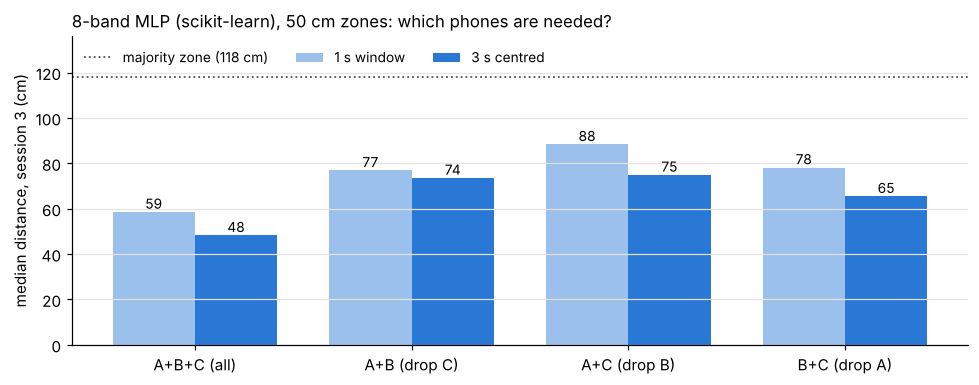

In [6]:
tc3 = t_centre[te_idx]; blk = ((tc3 - tc3[0]) // 30).astype(int); B = blk.max() + 1
rng = np.random.default_rng(0); picks = [np.concatenate([np.where(blk == b)[0] for b in rng.integers(0, B, B)]) for _ in range(5000)]
d_all = results["A+B+C (all)"]["test"]["d"]

print(f"{'phones':<16}{'median':>8}{'p90':>7}{'exact':>8}{'within 1':>10}{'3 s centred':>13}{'3 s causal':>12}   {'worse than all three (median, 95% CI)':<40}")
print(f"{'majority zone':<16}{base['median']:8.0f}{base['p90']:7.0f}{base['exact']:8.1%}{base['within1']:10.0%}")
summary = {}
for name, r in results.items():
    t = r["test"]; extra = ""
    if name != "A+B+C (all)":
        diffs = np.array([np.median(t["d"][ix]) - np.median(d_all[ix]) for ix in picks]); lo, hi = np.percentile(diffs, [2.5, 97.5])
        extra = f"{t['median'] - results['A+B+C (all)']['test']['median']:+.0f} cm  [{lo:+.0f}, {hi:+.0f}]"
    print(f"{name:<16}{t['median']:8.0f}{t['p90']:7.0f}{t['exact']:8.1%}{t['within1']:10.0%}{r['test_centred']['median']:13.0f}{r['test_causal']['median']:12.0f}   {extra}")
    summary[name] = {k: {m: v for m, v in r[k].items() if m != "d"} for k in ("val", "test", "test_centred", "test_causal")} | dict(epochs=r["epochs"], n_features=r["n_features"])
summary["majority zone"] = {m: v for m, v in base.items() if m != "d"}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1)

fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(results); xs = np.arange(len(names)); w = 0.38
ax.bar(xs - w / 2, [results[n]["test"]["median"] for n in names], w, color="#9cc0ec", label="1 s window")
ax.bar(xs + w / 2, [results[n]["test_centred"]["median"] for n in names], w, color="#2a78d6", label="3 s centred")
ax.axhline(base["median"], color="#555", ls=":", lw=1.2, label=f"majority zone ({base['median']:.0f} cm)")
for i, n in enumerate(names):
    for dx, v in ((-w / 2, results[n]["test"]["median"]), (w / 2, results[n]["test_centred"]["median"])):
        ax.text(i + dx, v + 1.5, f"{v:.0f}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_ylabel("median distance, session 3 (cm)")
ax.set_title("8-band MLP (scikit-learn), 50 cm zones: which phones are needed?", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, 1.0), ncol=3); ax.set_ylim(0, max(base["median"], 1) * 1.15)
ax.grid(axis="y", color="#e4e3df")
plt.tight_layout(); plt.savefig(OUT / "phone_ablation.png", dpi=150); plt.show()

# Verdict
*One test session (826 windows); the intervals cover the variation within session 3 only.*

**1. The re-implementation reproduces the zone notebook.** All three phones with the scikit-learn MLP: 59 cm median, 22% exact zone, 67% within one cell, against 60 cm, 21% and 66% for the PyTorch 8-band MLP in `experiment_zones.ipynb`. So the comparison below is on the same footing as the earlier results.

**2. Every phone matters; two phones are clearly worse than three.** Leaving one out raises the median error by 18–30 cm (77–88 cm), and in every case the 95% interval of the increase excludes zero (drop C: +9 to +29 cm; drop B: +19 to +40; drop A: +13 to +28). With two phones the model is still better than the majority zone (118 cm), but it loses about half of its gain over that baseline.

**3. Phone B carries the most.** Dropping B costs the most (88 cm). B is the only phone on the right side of the room (x = +1.7 m; A and C are at x = -2.1 and -0.9 m), so without it the right half is seen only from far away. Dropping C, the only phone at the back (y = +1.6 m), costs the least of the three, but the three intervals overlap, so the ranking is suggestive, not established.

**4. Combining 3 s of answers helps less with two phones.** All three phones: 59 → 48 cm; with two phones 65–75 cm. The time context cannot replace the missing spatial view.

## What this means for the plan
More spatial coverage is the lever: adding a microphone where the room is covered worst is likely to help more than a more complex model. It supports trying a fourth phone, or a multi-microphone array, in the next recordings. Not tested here: whether a fourth phone helps (that needs a new recording), and whether the ranking of phones holds in another session or room.

## Files written
* `phone_ablation_results/summary.json`: the numbers of the table
* `phone_ablation_results/phone_ablation.png`: the figure above